# NOTEBOOK 02: DATA PREPROCESSING & LEAKAGE PREVENTION
## Pipeline Design
- Stratified splitting into **Train (70%)**, **Validation (10%)**, and **Test (20%)** sets.
- Strict fitting of encoders and scalers **only on the training split**.
- Handling categorical variables (`gender`, `smoking_history`).
- Saving reproducible preprocessed datasets.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.join("..", "training_scripts"))
from data_loader import prepare_splits, load_raw_dataset, FEATURE_COLUMNS, TARGET_COLUMN

print("Executing stratified dataset preparation...")
splits = prepare_splits(test_size=0.2, val_size=0.1, random_state=42)

print(f"Training set:   {splits['X_train'].shape[0]:,} samples")
print(f"Validation set: {splits['X_val'].shape[0]:,} samples")
print(f"Test set:       {splits['X_test'].shape[0]:,} samples")


Executing stratified dataset preparation...


Training set:   70,000 samples
Validation set: 10,000 samples
Test set:       20,000 samples


### 2.1 Visualizing Class Proportions Across Splits (Stratification Proof)

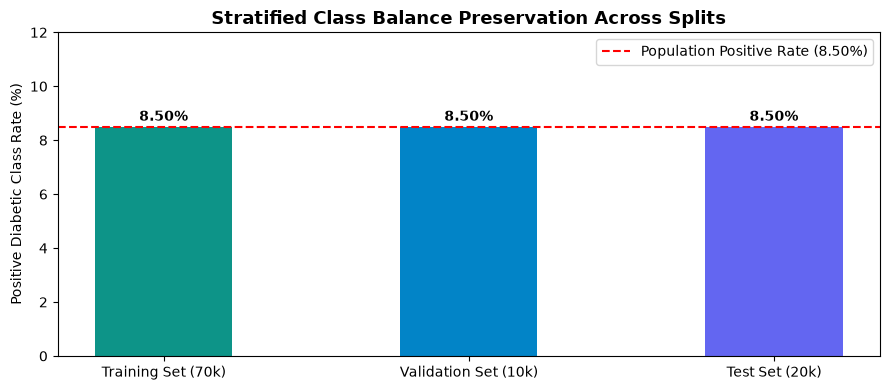

In [2]:
split_names = ['Training Set (70k)', 'Validation Set (10k)', 'Test Set (20k)']
pos_rates = [np.mean(splits['y_train']) * 100, np.mean(splits['y_val']) * 100, np.mean(splits['y_test']) * 100]

plt.figure(figsize=(9, 4))
bars = plt.bar(split_names, pos_rates, color=['#0d9488', '#0284c7', '#6366f1'], width=0.45)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.axhline(y=8.5, color='red', linestyle='--', label='Population Positive Rate (8.50%)')
plt.ylabel("Positive Diabetic Class Rate (%)")
plt.ylim(0, 12)
plt.title("Stratified Class Balance Preservation Across Splits", fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


### 2.2 Feature Scaling Transformation Visualizer (Raw vs Standardized)

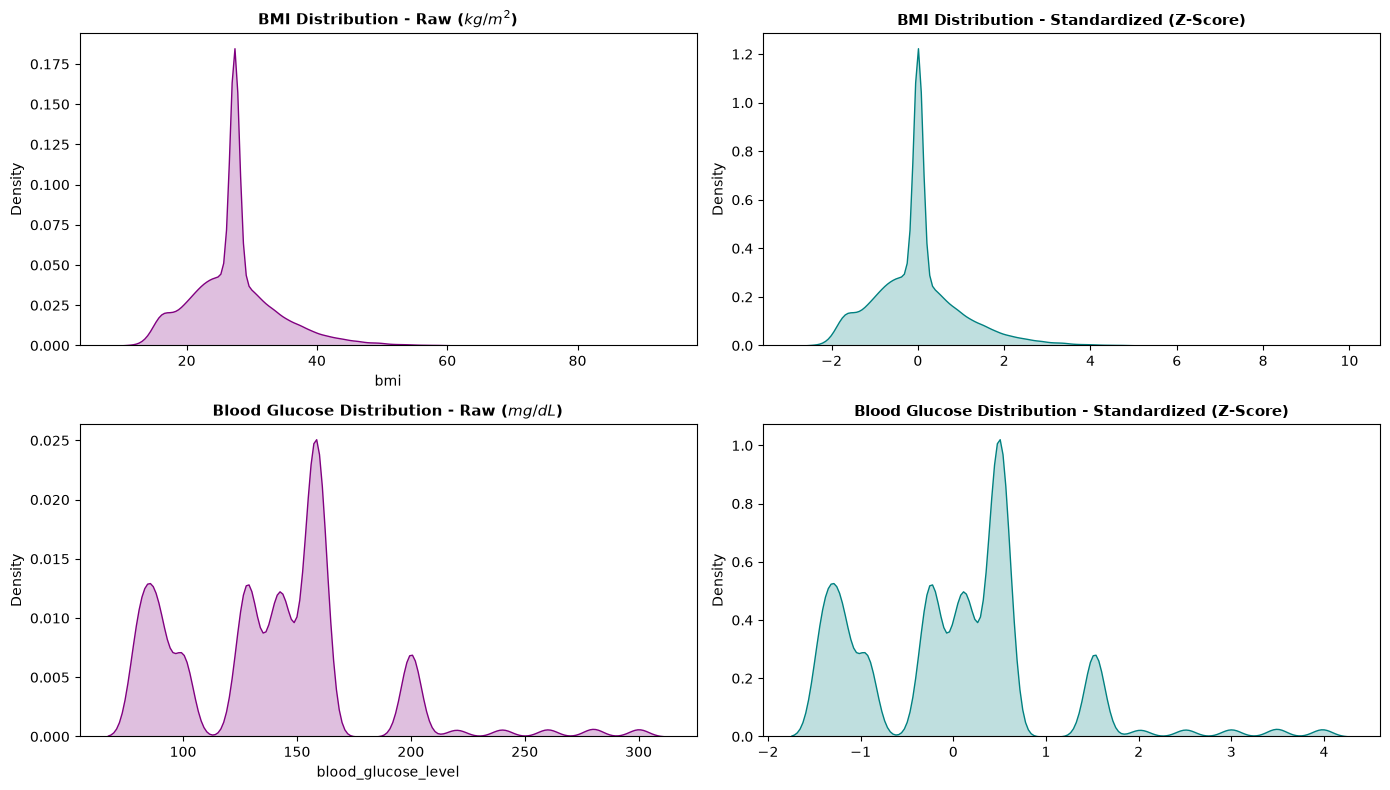

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Raw vs Scaled BMI
sns.kdeplot(splits['df_train']['bmi'], color='purple', fill=True, ax=axes[0, 0])
axes[0, 0].set_title("BMI Distribution - Raw ($kg/m^2$)", fontsize=11, fontweight='bold')

scaled_bmi = splits['X_train'][:, FEATURE_COLUMNS.index('bmi')]
sns.kdeplot(scaled_bmi, color='teal', fill=True, ax=axes[0, 1])
axes[0, 1].set_title("BMI Distribution - Standardized (Z-Score)", fontsize=11, fontweight='bold')

# Raw vs Scaled Glucose
sns.kdeplot(splits['df_train']['blood_glucose_level'], color='purple', fill=True, ax=axes[1, 0])
axes[1, 0].set_title("Blood Glucose Distribution - Raw ($mg/dL$)", fontsize=11, fontweight='bold')

scaled_glucose = splits['X_train'][:, FEATURE_COLUMNS.index('blood_glucose_level')]
sns.kdeplot(scaled_glucose, color='teal', fill=True, ax=axes[1, 1])
axes[1, 1].set_title("Blood Glucose Distribution - Standardized (Z-Score)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()
